# Repeat Purchase Prediction: Model Development

## Customer Intelligence Platform V2

### Objective

Develop and compare machine-learning models that predict whether a customer will make another purchase within 60 days of their first recorded purchase.

### Modelling Approach

- Use customer information associated with the first purchase.
- Apply chronological training, validation and test splits.
- Compare baseline, basket-based and product-category models.
- Evaluate customer-ranking performance using Average Precision, ROC AUC and targeting lift.
- Investigate class imbalance and model reliability.
- Reserve the test dataset for final evaluation.

### Data Source

Engineered customer-level features from `02_customer_feature_engineering.ipynb`.

### Reproducibility

This notebook will load a saved feature dataset rather than rely on variables stored in another notebook's active Python session.


In [21]:
# Restructuring Step 4: Load engineered customer features

from pathlib import Path
import pandas as pd
import numpy as np

# Locate the project folder
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Locate the saved dataset
feature_path = (
    project_root / "data" / "processed" / "customer_features.pkl"
)

# Load the locally generated, trusted dataset
customer_features = pd.read_pickle(feature_path)

# Verify the loaded dataset
print("Dataset loaded successfully!")
print("File exists:", feature_path.is_file())
print("Dataset shape:", customer_features.shape)
print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)
print(
    "Missing target values:",
    customer_features["repeat_purchase_60d"].isna().sum()
)

Dataset loaded successfully!
File exists: True
Dataset shape: (78100, 29)
Unique customers: 78100
Missing target values: 0


In [22]:
# Restructuring Step 6: Inspect date information for chronological splitting

print("Date-related columns:")
print([
    column for column in customer_features.columns
    if "date" in column.lower() or "timestamp" in column.lower()
])

print("\nFirst-order purchase timestamp type:")
print(customer_features["order_purchase_timestamp"].dtype)

print("\nFirst-order purchase date range:")
print("Earliest:", customer_features["order_purchase_timestamp"].min())
print("Latest:", customer_features["order_purchase_timestamp"].max())

print("\nMissing purchase timestamps:")
print(customer_features["order_purchase_timestamp"].isna().sum())

Date-related columns:
['order_purchase_timestamp']

First-order purchase timestamp type:
datetime64[us]

First-order purchase date range:
Earliest: 2016-09-04 21:15:19
Latest: 2018-06-02 23:42:33

Missing purchase timestamps:
0


In [23]:
# Restructuring Step 7: Recreate and validate chronological splits

# First-purchase timestamps
dates = customer_features["order_purchase_timestamp"]

# Reconstruct the assumed 90-day label-observation timeline
label_ends = dates + pd.Timedelta(days=90)

# Original chronological boundaries
train_end_c = pd.Timestamp("2017-06-30 23:59:59")
validation_start_c = pd.Timestamp("2017-10-01")
validation_end_c = pd.Timestamp("2017-12-31 23:59:59")
test_start_c = pd.Timestamp("2018-04-01")

# Recreate original split logic
train_mask_c = (
    (dates <= train_end_c)
    & (label_ends < validation_start_c)
)

validation_mask_c = (
    (dates >= validation_start_c)
    & (dates <= validation_end_c)
    & (label_ends < test_start_c)
)

test_mask_c = dates >= test_start_c

# Validate split populations
print("Training customers:", train_mask_c.sum())
print("Validation customers:", validation_mask_c.sum())
print("Testing customers:", test_mask_c.sum())

print("\nTraining repeat purchasers:",
      customer_features.loc[train_mask_c, "repeat_purchase_60d"].sum())

print("Validation repeat purchasers:",
      customer_features.loc[validation_mask_c, "repeat_purchase_60d"].sum())

print("Testing repeat purchasers:",
      customer_features.loc[test_mask_c, "repeat_purchase_60d"].sum())

print("\nOverlapping split assignments:",
      ((train_mask_c.astype(int)
        + validation_mask_c.astype(int)
        + test_mask_c.astype(int)) > 1).sum())

Training customers: 14554
Validation customers: 17257
Testing customers: 13649

Training repeat purchasers: 321
Validation repeat purchasers: 331
Testing repeat purchasers: 199

Overlapping split assignments: 0


## Chronological Data Splitting

### Objective

Evaluate repeat-purchase prediction using historical customer cohorts while reducing the risk of information leakage between training, validation and testing.

### Split Design

| Dataset | First-Purchase Period | Customers | Repeat Purchasers |
|---|---|---:|---:|
| Training | Up to June 30, 2017 | 14,554 | 321 |
| Validation | October 1 to December 31, 2017 | 17,257 | 331 |
| Test | April 1, 2018 onward | 13,649 | 199 |

### Methodology

- Customers are assigned according to their first recorded purchase timestamp.
- A 90-day observation window is assumed, comprising 60 days for repeat-purchase observation and a further 30-day delivery-outcome buffer.
- Unused periods between the datasets allow time for outcomes to mature.
- No customers belong to more than one split.
- The test population is reserved for final model evaluation.

### Interpretation and Limitations

Chronological splitting provides a more realistic historical evaluation than randomly distributing customers across time.

However, the 90-day buffer is an observation-window assumption, not proof that every delivery outcome was fully resolved. Historical availability of all predictive features must also be verified before claiming the model could have operated at the time of the first purchase.

The modelling process will use the training and validation populations for development, keeping the test dataset separate until final evaluation.

In [24]:
# Restructuring Step 9: Define modelling feature groups

# Baseline customer and purchase-timing features
baseline_feature_columns = [
    "customer_state",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

# First-order basket features
basket_feature_columns = [
    "first_order_item_count",
    "first_order_product_count",
    "first_order_item_value",
    "first_order_freight_value"
]

# Primary product-category feature
category_feature_columns = [
    "first_order_primary_category"
]

# Define experimental feature groups
basket_experiment_features = (
    baseline_feature_columns + basket_feature_columns
)

category_experiment_features = (
    basket_experiment_features + category_feature_columns
)

# Verify all modelling features exist
all_modelling_features = list(dict.fromkeys(
    category_experiment_features
))

missing_features = [
    column for column in all_modelling_features
    if column not in customer_features.columns
]

print("Baseline features:", len(baseline_feature_columns))
print("Baseline + basket features:", len(basket_experiment_features))
print("Baseline + basket + category features:",
      len(category_experiment_features))

print("\nMissing features:", missing_features)

print("\nFinal candidate feature list:")
for feature in category_experiment_features:
    print("-", feature)

Baseline features: 4
Baseline + basket features: 8
Baseline + basket + category features: 9

Missing features: []

Final candidate feature list:
- customer_state
- purchase_month
- purchase_day_of_week
- purchase_hour
- first_order_item_count
- first_order_product_count
- first_order_item_value
- first_order_freight_value
- first_order_primary_category


In [25]:
# Restructuring Step 10: Prepare matched modelling datasets

target_column = "repeat_purchase_60d"

# Require complete basket and category information
complete_feature_mask = customer_features[
    basket_feature_columns + category_feature_columns
].notna().all(axis=1)

# Combine completeness requirements with chronological splits
category_train_mask = train_mask_c & complete_feature_mask
category_validation_mask = validation_mask_c & complete_feature_mask

# Prepare training features and target
X_train_category = customer_features.loc[
    category_train_mask, category_experiment_features
].copy()

y_train_category = customer_features.loc[
    category_train_mask, target_column
].copy()

# Prepare validation features and target
X_validation_category = customer_features.loc[
    category_validation_mask, category_experiment_features
].copy()

y_validation_category = customer_features.loc[
    category_validation_mask, target_column
].copy()

# Verify matched modelling populations
print("Training customers:", len(X_train_category))
print("Training repeat purchasers:", int(y_train_category.sum()))

print("\nValidation customers:", len(X_validation_category))
print("Validation repeat purchasers:", int(y_validation_category.sum()))

print("\nTraining missing feature values:",
      int(X_train_category.isna().sum().sum()))

print("Validation missing feature values:",
      int(X_validation_category.isna().sum().sum()))

Training customers: 14051
Training repeat purchasers: 308

Validation customers: 16772
Validation repeat purchasers: 323

Training missing feature values: 0
Validation missing feature values: 0


In [26]:
# Restructuring Step 11: Build the modelling preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Numerical features
numerical_features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "first_order_item_count",
    "first_order_product_count",
    "first_order_item_value",
    "first_order_freight_value"
]

# Categorical features
categorical_features = [
    "customer_state",
    "first_order_primary_category"
]

# Scale numerical variables and encode categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Create our unweighted Logistic Regression pipeline
unweighted_category_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight=None,
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Preprocessing pipeline created successfully!")
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Model:", type(
    unweighted_category_pipeline.named_steps["classifier"]
).__name__)
print("Class weighting:",
      unweighted_category_pipeline.named_steps["classifier"].class_weight)

Preprocessing pipeline created successfully!
Numerical features: 7
Categorical features: 2
Model: LogisticRegression
Class weighting: None


In [27]:
# Restructuring Step 12: Train the unweighted Logistic Regression model

# Fit preprocessing and model using training data only
unweighted_category_pipeline.fit(
    X_train_category,
    y_train_category
)

# Retrieve the fitted classifier
trained_classifier = (
    unweighted_category_pipeline.named_steps["classifier"]
)

# Check training results
print("Model trained successfully!")

print("Training customers:", len(X_train_category))
print("Training repeat purchasers:", int(y_train_category.sum()))

print(
    "Encoded features:",
    len(
        unweighted_category_pipeline
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )
)

print(
    "Training iterations:",
    trained_classifier.n_iter_[0]
)

print(
    "Model classes:",
    trained_classifier.classes_
)

Model trained successfully!
Training customers: 14051
Training repeat purchasers: 308
Encoded features: 102
Training iterations: 38
Model classes: [0 1]


In [28]:
#  Evaluate validation performance

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# Generate validation probabilities
unweighted_validation_scores = (
    unweighted_category_pipeline.predict_proba(
        X_validation_category
    )[:, 1]
)

# Calculate evaluation metrics
validation_results = {
    "Average Precision": average_precision_score(
        y_validation_category,
        unweighted_validation_scores
    ),
    "ROC AUC": roc_auc_score(
        y_validation_category,
        unweighted_validation_scores
    ),
    "Brier Score": brier_score_loss(
        y_validation_category,
        unweighted_validation_scores
    ),
    "Log Loss": log_loss(
        y_validation_category,
        unweighted_validation_scores
    )
}

print("Validation Model Performance")
print("-" * 35)

for metric, value in validation_results.items():
    print(f"{metric}: {value:.4f}")

print("\nObserved repeat-purchase rate:",
      f"{y_validation_category.mean():.4%}")

print("Average predicted probability:",
      f"{unweighted_validation_scores.mean():.4%}")

Validation Model Performance
-----------------------------------
Average Precision: 0.0375
ROC AUC: 0.6305
Brier Score: 0.0189
Log Loss: 0.0938

Observed repeat-purchase rate: 1.9258%
Average predicted probability: 2.3541%


In [39]:
# Compare Logistic Regression against a no-skill probability baseline

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# Use the training population's observed repeat-purchase rate
training_repeat_rate = y_train_category.mean()

# Assign the same probability to every validation customer
baseline_scores = np.full(
    len(y_validation_category),
    training_repeat_rate
)

# Calculate baseline performance
baseline_results = {
    "Average Precision": average_precision_score(
        y_validation_category, baseline_scores
    ),
    "ROC AUC": roc_auc_score(
        y_validation_category, baseline_scores
    ),
    "Brier Score": brier_score_loss(
        y_validation_category, baseline_scores
    ),
    "Log Loss": log_loss(
        y_validation_category, baseline_scores
    )
}

# Compare against the existing Logistic Regression results
comparison = pd.DataFrame({
    "No-Skill Baseline": baseline_results,
    "Logistic Regression": validation_results
})

print("Model vs No-Skill Baseline")
print("-" * 45)

display(comparison.round(4))

print(
    "Training repeat-purchase rate:",
    f"{training_repeat_rate:.4%}"
)

Model vs No-Skill Baseline
---------------------------------------------


,No-Skill Baseline,Logistic Regression
Average Precision,0.0193,0.0375
ROC AUC,0.5000,0.6305
Brier Score,0.0189,0.0189
Log Loss,0.0953,0.0938


Training repeat-purchase rate: 2.1920%


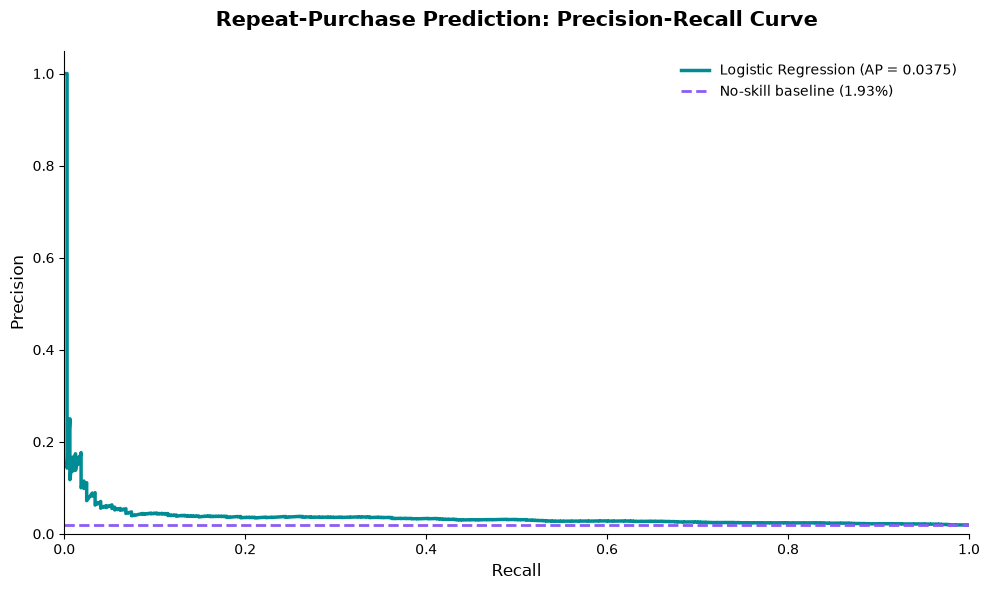

In [29]:
# Restructuring Step 14: Visualise validation Precision-Recall performance

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Calculate precision and recall across thresholds
precision, recall, thresholds = precision_recall_curve(
    y_validation_category,
    unweighted_validation_scores
)

# Calculate no-skill baseline
baseline_precision = y_validation_category.mean()

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Model Precision-Recall Curve
ax.plot(
    recall,
    precision,
    color="#008C95",
    linewidth=2.5,
    label=f"Logistic Regression (AP = {validation_results['Average Precision']:.4f})"
)

# No-skill reference
ax.axhline(
    y=baseline_precision,
    color="#8B5CF6",
    linestyle="--",
    linewidth=2,
    label=f"No-skill baseline ({baseline_precision:.2%})"
)

# Chart formatting
ax.set_title(
    "Repeat-Purchase Prediction: Precision-Recall Curve",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)

ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)

ax.legend(frameon=False, fontsize=10)

# Remove unnecessary chart elements
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Precision-Recall Analysis

**Objective:** Evaluate how effectively the unweighted Logistic Regression model ranks customers by their likelihood of making a repeat purchase within 60 days.

**Validation results:**

- Validation customers: 16,772
- Observed repeat purchasers: 323
- Repeat-purchase rate: 1.93%
- Average Precision: 0.0375
- ROC AUC: 0.6305

**Key findings:**

The model achieves an Average Precision approximately 1.95 times the no-skill baseline, demonstrating modest predictive ranking capability.

Precision declines as recall increases, indicating that identifying a broader proportion of returning customers requires including more customers who do not subsequently return.

Because repeat purchasing is rare, even a model that performs better than random targeting can have relatively low precision.

**Business interpretation:**

The model may help prioritise customers for further retention analysis or controlled targeting experiments. However, the current evidence is insufficient to establish that a model-based retention campaign would generate incremental revenue or positive return on investment.

**Limitations:**

- Performance was measured on historical validation data.
- The model's usefulness depends on campaign costs, targeting capacity and treatment effectiveness.
- Ranking performance and probability calibration require separate assessment.
- Temporal stability analysis identified weaker model performance in later validation months.
- The reserved test dataset has not yet been evaluated.

**Next step:** Compare customer-targeting performance at practical campaign sizes and assess whether the model identifies more repeat purchasers than untargeted selection.

In [30]:
# Restructuring Step 16: Evaluate customer targeting by campaign size

from sklearn.metrics import roc_auc_score

# Prepare validation targeting results
targeting_data = pd.DataFrame({
    "actual_return": y_validation_category.to_numpy(),
    "predicted_score": unweighted_validation_scores
})

total_customers = len(targeting_data)
total_returners = int(targeting_data["actual_return"].sum())
overall_return_rate = targeting_data["actual_return"].mean()

# Evaluate multiple targeting budgets
targeting_results = []

for budget in [0.05, 0.10, 0.20]:

    customers_targeted = int(np.ceil(total_customers * budget))

    # Identify the highest-scoring customers
    top_customers = targeting_data.nlargest(
        customers_targeted,
        "predicted_score"
    )

    returners_identified = int(
        top_customers["actual_return"].sum()
    )

    expected_random_returners = (
        customers_targeted * overall_return_rate
    )

    targeting_results.append({
        "targeting_budget": f"{budget:.0%}",
        "customers_targeted": customers_targeted,
        "returners_identified": returners_identified,
        "expected_random_returners": expected_random_returners,
        "precision_pct": (
            returners_identified / customers_targeted * 100
        ),
        "recall_pct": (
            returners_identified / total_returners * 100
        ),
        "lift": (
            returners_identified / expected_random_returners
        )
    })

targeting_summary = pd.DataFrame(targeting_results)

print("Customer Targeting Performance")
print("-" * 45)

print(
    targeting_summary.round(2).to_string(index=False)
)

print("\nTotal validation customers:", total_customers)
print("Total repeat purchasers:", total_returners)

Customer Targeting Performance
---------------------------------------------
targeting_budget  customers_targeted  returners_identified  expected_random_returners  precision_pct  recall_pct  lift
              5%                 839                    36                      16.16           4.29       11.15  2.23
             10%                1678                    63                      32.32           3.75       19.50  1.95
             20%                3355                   117                      64.61           3.49       36.22  1.81

Total validation customers: 16772
Total repeat purchasers: 323


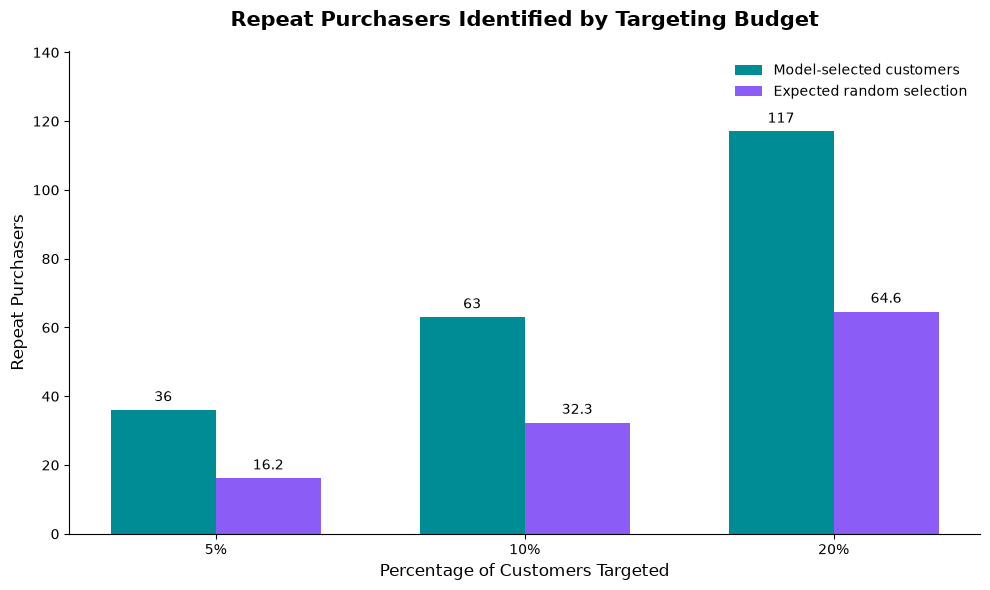

In [31]:
# Restructuring Step 17: Visualise customer-targeting performance

import matplotlib.pyplot as plt
import numpy as np

# Prepare chart data
budgets = targeting_summary["targeting_budget"]
model_returners = targeting_summary["returners_identified"]
random_returners = targeting_summary["expected_random_returners"]
lift_values = targeting_summary["lift"]

x = np.arange(len(budgets))
bar_width = 0.34

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Model results
model_bars = ax.bar(
    x - bar_width / 2,
    model_returners,
    bar_width,
    color="#008C95",
    label="Model-selected customers"
)

# Random-selection expectations
random_bars = ax.bar(
    x + bar_width / 2,
    random_returners,
    bar_width,
    color="#8B5CF6",
    label="Expected random selection"
)

# Add numeric labels
ax.bar_label(
    model_bars,
    labels=[f"{v:.0f}" for v in model_returners],
    padding=4
)

ax.bar_label(
    random_bars,
    labels=[f"{v:.1f}" for v in random_returners],
    padding=4
)

# Chart formatting
ax.set_title(
    "Repeat Purchasers Identified by Targeting Budget",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Percentage of Customers Targeted", fontsize=12)
ax.set_ylabel("Repeat Purchasers", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(budgets)

ax.set_ylim(0, max(model_returners) * 1.2)

ax.legend(frameon=False)

# Remove unnecessary visual elements
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Customer Targeting Performance and Business Interpretation

**Objective**

Evaluate whether the repeat-purchase prediction model can identify customers who subsequently return more effectively than random selection at different targeting budgets.

**Validation results**

| Targeting Budget | Customers Targeted | Returners Identified | Expected Random Returners | Lift |
|---|---:|---:|---:|---:|
| 5% | 839 | 36 | 16.16 | 2.23× |
| 10% | 1,678 | 63 | 32.32 | 1.95× |
| 20% | 3,355 | 117 | 64.61 | 1.81× |

**Key findings**

- The highest-scoring 5% of customers contained approximately 2.23 times as many observed

In [32]:
# Restructuring Step 19: Check prediction-score ties at targeting boundaries

tie_check_results = []

for budget in [0.05, 0.10, 0.20]:

    n_targeted = int(np.ceil(len(targeting_data) * budget))

    # Sort customers by predicted score, highest first
    sorted_scores = (
        targeting_data["predicted_score"]
        .sort_values(ascending=False)
        .reset_index(drop=True)
    )

    # Score of the last selected customer
    boundary_score = sorted_scores.iloc[n_targeted - 1]

    # Count all customers with this exact score
    customers_at_boundary = int(
        (sorted_scores == boundary_score).sum()
    )

    # Count customers strictly above the boundary
    customers_above_boundary = int(
        (sorted_scores > boundary_score).sum()
    )

    # Determine whether the tie crosses the selection boundary
    tie_crosses_boundary = (
        customers_above_boundary < n_targeted
        < customers_above_boundary + customers_at_boundary
    )

    tie_check_results.append({
        "budget": f"{budget:.0%}",
        "customers_targeted": n_targeted,
        "boundary_score": boundary_score,
        "customers_with_boundary_score": customers_at_boundary,
        "tie_crosses_boundary": tie_crosses_boundary
    })

tie_check_summary = pd.DataFrame(tie_check_results)

print("Prediction Score Tie Analysis")
print("-" * 45)

print(
    tie_check_summary.to_string(index=False)
)

Prediction Score Tie Analysis
---------------------------------------------
budget  customers_targeted  boundary_score  customers_with_boundary_score  tie_crosses_boundary
    5%                 839        0.057446                              1                 False
   10%                1678        0.048313                              1                 False
   20%                3355        0.033971                              1                 False


### Targeting Boundary Validation

**Objective**

Verify that the customer-targeting results at 5%, 10% and 20% budgets are not sensitive to tied prediction scores at the selection boundaries.

**Findings**

| Targeting Budget | Customers Selected | Customers Sharing Boundary Score | Boundary Tie |
|---|---:|---:|---|
| 5% | 839 | 1 | No |
| 10% | 1,678 | 1 | No |
| 20% | 3,355 | 1 | No |

**Interpretation**

None of the evaluated targeting boundaries splits a group of customers with identical predicted scores.

The previously calculated top-N targeting results are therefore unaffected by score-tie selection ambiguity at these budgets.

The model identified 36, 63 and 117 observed repeat purchasers at the 5%, 10% and 20% targeting budgets, respectively.

**Limitations**

- Results are based on historical validation data.
- The analysis establishes ranking consistency at the evaluated budget boundaries, not the stability of future model performance.
- Targeting lift measures concentration of naturally returning customers, not incremental campaign effectiveness.
- Final test-set evaluation remains outstanding.

**Conclusion**

The evaluated customer-targeting results can be retained as validated historical ranking results, subject to the broader limitations of the model.

In [33]:
# Restructuring Step 21: Prepare matched model-comparison datasets

# Baseline features
X_train_baseline = X_train_category[
    baseline_feature_columns
].copy()

X_validation_baseline = X_validation_category[
    baseline_feature_columns
].copy()

# Baseline + basket features
X_train_basket = X_train_category[
    basket_experiment_features
].copy()

X_validation_basket = X_validation_category[
    basket_experiment_features
].copy()

# Confirm all experiments use the same customers
print("Matched Model Comparison Populations")
print("-" * 45)

print("Training customers:")
print("Baseline:", len(X_train_baseline))
print("Basket:", len(X_train_basket))
print("Combined:", len(X_train_category))

print("\nValidation customers:")
print("Baseline:", len(X_validation_baseline))
print("Basket:", len(X_validation_basket))
print("Combined:", len(X_validation_category))

print("\nFeature counts:")
print("Baseline:", X_train_baseline.shape[1])
print("Basket:", X_train_basket.shape[1])
print("Combined:", X_train_category.shape[1])

print("\nTraining indices aligned:",
      X_train_baseline.index.equals(X_train_category.index)
      and X_train_basket.index.equals(X_train_category.index))

print("Validation indices aligned:",
      X_validation_baseline.index.equals(X_validation_category.index)
      and X_validation_basket.index.equals(X_validation_category.index))

Matched Model Comparison Populations
---------------------------------------------
Training customers:
Baseline: 14051
Basket: 14051
Combined: 14051

Validation customers:
Baseline: 16772
Basket: 16772
Combined: 16772

Feature counts:
Baseline: 4
Basket: 8
Combined: 9

Training indices aligned: True
Validation indices aligned: True


In [34]:
# Restructuring Step 22: Train matched baseline and basket models

from sklearn.base import clone

# Baseline preprocessing
baseline_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            [
                "purchase_month",
                "purchase_day_of_week",
                "purchase_hour"
            ]
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["customer_state"]
        )
    ]
)

# Basket preprocessing
basket_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["customer_state"]
        )
    ]
)

# Use the same classifier configuration as the combined model
baseline_pipeline = Pipeline(
    steps=[
        ("preprocessor", baseline_preprocessor),
        (
            "classifier",
            clone(
                unweighted_category_pipeline.named_steps["classifier"]
            )
        )
    ]
)

basket_pipeline = Pipeline(
    steps=[
        ("preprocessor", basket_preprocessor),
        (
            "classifier",
            clone(
                unweighted_category_pipeline.named_steps["classifier"]
            )
        )
    ]
)

# Train both models
baseline_pipeline.fit(X_train_baseline, y_train_category)

basket_pipeline.fit(X_train_basket, y_train_category)

print("Both comparison models trained successfully!")

print(
    "Baseline encoded features:",
    len(baseline_pipeline.named_steps["preprocessor"].get_feature_names_out())
)

print(
    "Basket encoded features:",
    len(basket_pipeline.named_steps["preprocessor"].get_feature_names_out())
)

print(
    "Baseline training iterations:",
    baseline_pipeline.named_steps["classifier"].n_iter_[0]
)

print(
    "Basket training iterations:",
    basket_pipeline.named_steps["classifier"].n_iter_[0]
)

Both comparison models trained successfully!
Baseline encoded features: 30
Basket encoded features: 34
Baseline training iterations: 24
Basket training iterations: 34


In [35]:
# Compare three modelling approaches

# Generate validation probabilities
baseline_validation_scores = baseline_pipeline.predict_proba(
    X_validation_baseline
)[:, 1]

basket_validation_scores = basket_pipeline.predict_proba(
    X_validation_basket
)[:, 1]

# Reuse combined-model validation probabilities
combined_validation_scores = unweighted_validation_scores

# Store model predictions
model_predictions = {
    "Baseline": baseline_validation_scores,
    "Basket": basket_validation_scores,
    "Combined": combined_validation_scores
}

# Calculate observed repeat-purchase rate
baseline_return_rate = y_validation_category.mean()

# Compare models using the same validation customers
comparison_results = []

for model_name, scores in model_predictions.items():

    ap = average_precision_score(
        y_validation_category, scores
    )

    comparison_results.append({
        "Model": model_name,
        "Average Precision": ap,
        "ROC AUC": roc_auc_score(
            y_validation_category, scores
        ),
        "Brier Score": brier_score_loss(
            y_validation_category, scores
        ),
        "AP Lift": ap / baseline_return_rate
    })

model_comparison = pd.DataFrame(comparison_results)

print("Matched Model Performance Comparison")
print("-" * 50)

print(model_comparison.round(4).to_string(index=False))

print("\nValidation customers:", len(y_validation_category))
print(
    "Observed repeat-purchase rate:",
    f"{baseline_return_rate:.2%}"
)

Matched Model Performance Comparison
--------------------------------------------------
   Model  Average Precision  ROC AUC  Brier Score  AP Lift
Baseline             0.0205   0.5197       0.0189   1.0642
  Basket             0.0309   0.5622       0.0189   1.6031
Combined             0.0375   0.6305       0.0189   1.9496

Validation customers: 16772
Observed repeat-purchase rate: 1.93%


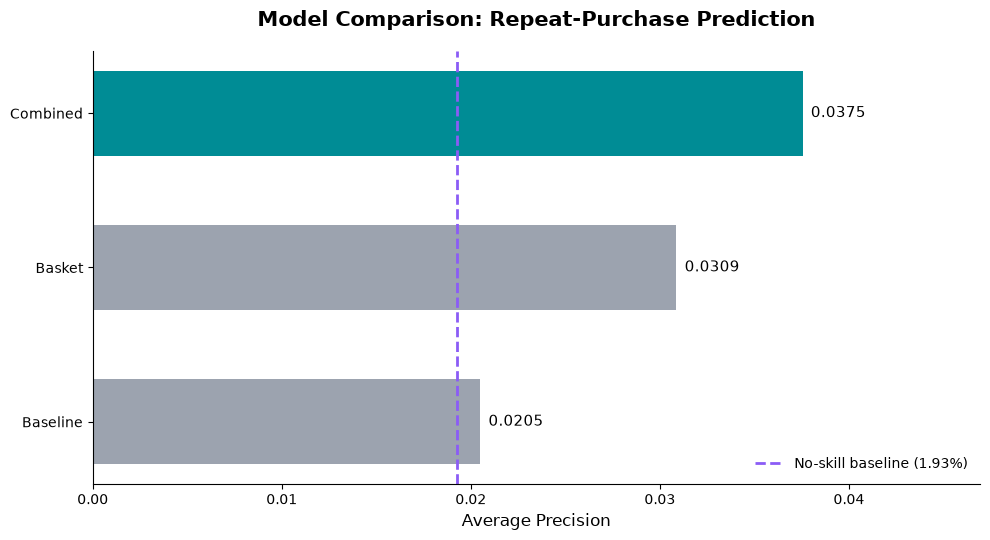

In [36]:
#  Visualise model comparison

import matplotlib.pyplot as plt

# Order models from lowest to highest Average Precision
plot_data = model_comparison.sort_values(
    "Average Precision"
)

# Highlight the strongest model
colors = [
    "#9CA3AF" if model != "Combined" else "#008C95"
    for model in plot_data["Model"]
]

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    plot_data["Model"],
    plot_data["Average Precision"],
    color=colors,
    height=0.55
)

# No-skill baseline
ax.axvline(
    baseline_return_rate,
    color="#8B5CF6",
    linestyle="--",
    linewidth=2,
    label=f"No-skill baseline ({baseline_return_rate:.2%})"
)

# Display values at the ends of bars
ax.bar_label(
    bars,
    labels=[
        f"{value:.4f}"
        for value in plot_data["Average Precision"]
    ],
    padding=6,
    fontsize=11
)

ax.set_title(
    "Model Comparison: Repeat-Purchase Prediction",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Average Precision", fontsize=12)
ax.set_ylabel("")

ax.set_xlim(
    0,
    plot_data["Average Precision"].max() * 1.25
)

ax.legend(frameon=False, loc="lower right")

# Clean presentation
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Model Comparison and Candidate Selection

**Objective**

Compare three Logistic Regression models to determine whether first-order basket information and product-category information improve repeat-purchase prediction.

All three models were trained on the same 14,051 customers and evaluated on the same 16,772 validation customers.

#### Validation Results

| Model | Average Precision | ROC AUC | AP Lift |
|---|---:|---:|---:|
| Baseline | 0.0205 | 0.5197 | 1.06× |
| Basket | 0.0309 | 0.5622 | 1.60× |
| Combined | **0.0375** | **0.6305** | **1.95×** |

The observed repeat-purchase rate was approximately 1.93%.

#### Key Findings

- The Baseline model showed limited ability to distinguish returning customers from non-returning customers.
- Adding first-order basket features improved both Average Precision and ROC AUC.
- Including primary product category produced the strongest ranking performance among the three models.
- All three models produced Brier Scores of approximately 0.0189 when rounded to four decimal places. More precise comparisons would be needed to distinguish their probability errors.

#### Model-Selection Decision

The nine-feature Combined Logistic Regression model is retained as the leading candidate for further evaluation.

This decision is based primarily on its superior Average Precision, ROC AUC and ranking lift on the matched validation population.

#### Limitations

The model still has modest predictive power, and stronger historical ranking does not establish that model-based retention campaigns would generate incremental purchases.

Earlier temporal-stability analysis also identified weaker performance in later validation months.

The model therefore requires additional reliability assessment before final holdout evaluation.



In [37]:
# Save the trained model

from pathlib import Path
import joblib

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Create model output directory
model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Define model file path
model_path = model_dir / "repeat_purchase_logistic_regression.joblib"

# Save the complete fitted pipeline
joblib.dump(
    unweighted_category_pipeline,
    model_path
)

# Verify the saved file
print("Model saved successfully:", model_path.is_file())
print("Model location:", model_path)
print("Model type:", type(
    unweighted_category_pipeline.named_steps["classifier"]
).__name__)

print("Training customers:", len(X_train_category))
print("Validation customers:", len(X_validation_category))

Model saved successfully: True
Model location: c:\Users\oades\Downloads\Downloads\customer-intelligence-platform\models\repeat_purchase_logistic_regression.joblib
Model type: LogisticRegression
Training customers: 14051
Validation customers: 16772


In [38]:
# Verify the saved model

import joblib
import numpy as np

# Load the saved model
loaded_model = joblib.load(model_path)

# Generate predictions using the loaded model
loaded_validation_scores = loaded_model.predict_proba(
    X_validation_category
)[:, 1]

# Compare with our original predictions
predictions_match = np.allclose(
    unweighted_validation_scores,
    loaded_validation_scores,
    rtol=0,
    atol=1e-12
)

maximum_difference = np.max(
    np.abs(
        unweighted_validation_scores
        - loaded_validation_scores
    )
)

print("Saved model loaded successfully!")
print("Predictions match:", predictions_match)
print("Maximum prediction difference:", maximum_difference)
print("Validation customers:", len(loaded_validation_scores))

Saved model loaded successfully!
Predictions match: True
Maximum prediction difference: 0.0
Validation customers: 16772
